In [1]:
from ASDCache import SpectraCache
import yaml
import pandas as pd

In [2]:
def generate_YAML_data(levels, N=30, show_fine_structure=True, labels=True, label_fine_structure=False):
    data = {'format': 'grotrian',
            'version': 1,
            'diagram': {
                'title': "Auto-generated YAML",
                'vertical_axis': {'property': 'Energy (cm-1)', 'unit': 'cm-1'},
                'horizontal_axis': {'order': []} # Filled later!
            }}
    
    out_levels = []
    cols = []
    groups = {}
    
    for i, level in levels.head(N).iterrows():
        J, g, L = level['J'], level['g'], level['L']
        config, term = level['Configuration'], level['Term']
        if pd.isna(J) or pd.isna(term) or pd.isna(config):
            continue
        energ = level['Level (cm-1)']
        
        col = term
    
        group_id = f"{config}_{term}"
        if group_id not in groups:
            groups[group_id] = [level]
        else:
            groups[group_id].append(level)
    
        if col not in cols:
            cols.append(col)
        
    data['diagram']['horizontal_axis']['order'] = cols
    
    for g_id, group in groups.items():
        level=group[0]
        if len(group) == 1:
            J, g, L = level['J'], level['g'], level['L']
            config, term = level['Configuration'], level['Term']
            energ = level['Level (cm-1)']
    
            col = term
            lvl_id = f"{config}_{term}_{J}"
            lbl = ""
            if labels:
                lbl = f"{config}_{term}"
            
            out_level = {'id': lvl_id,
                         'label': lbl,
                         'col': col,
                         'energy': energ }
        else:        
            g, L = level['g'], level['L']
            config, term = level['Configuration'], level['Term']
    
            e_mean = []
            for l in group:
                e_mean.append(l['Level (cm-1)'])
            energ = sum(e_mean)/len(e_mean)
    
            col = term
            lvl_id = f"{config}_{term}"
            lbl = ""
            if labels:
                lbl = f"{config}_{term}"
    
            out_level = {'id': lvl_id,
                         'label': lbl,
                         'col': col,
                         'energy': energ }
    
            split_levels = []
            for l in group:
                J = l['J']
                split_id = f"{config}_{term}_{J}"
                split_lbl = ""
                if label_fine_structure:
                    split_lbl = f"$j={int(J*2)}/2$"
                split_level = {'id': split_id,
                             'label': split_lbl,
                             'offset': l['Level (cm-1)'] - energ,
                             'loc': 'right' }
                split_levels.append(split_level)
                
            if show_fine_structure:
                out_level['split'] = split_levels
            
        out_levels.append(out_level)
    
    data['levels'] = out_levels

    return data

In [3]:
nist = SpectraCache()
levels = nist.levels.fetch("Rb I")

data = generate_YAML_data(levels, show_fine_structure=False, labels=True, N=20)

with open("test.yaml", "w", encoding="utf-8") as yaml_file:
    yaml.dump(
        data, 
        yaml_file, 
        default_flow_style=False,  # Forces block style (clean indentation)
        sort_keys=False            # Keeps the exact dictionary order from Python
    )

In [4]:
from grotrian import Grotrian

/home/jaymz/.local/pipx-sys-envs/jupyterlab/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


<Axes: title={'center': 'Auto-generated YAML'}, ylabel='Energy (cm-1)'>

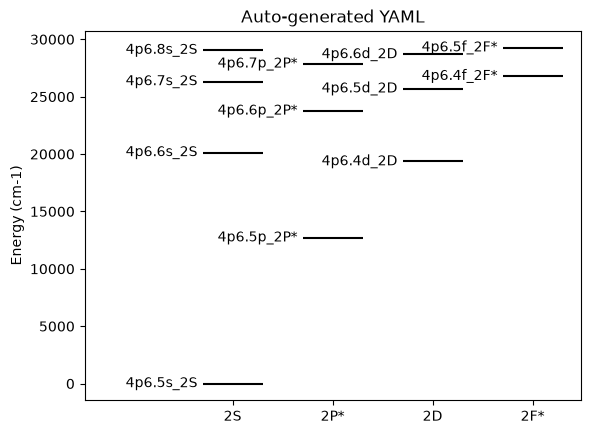

In [5]:
e = Grotrian('test.yaml')
e.draw(ax_expan_l=1.0, delta_p=0.5, delta_c=0.3)